# 18 客層・時間帯別の商品需要と注文時刻

全店舗の注文明細を会計ID・来店グループIDで来店ログに結合し、客層・時間帯・カテゴリごとの数量と売上を調べる。異なる時刻の追加注文を同一会計として扱う。

来店ログと注文実績は2022〜2024年に限る。2025年の同日の客層・注文時刻や他商品実績は未知で、直接の特徴量には使えない。すべての比較は観察上の関連であり、因果効果を示さない。

In [1]:
from pathlib import Path
import zipfile,io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.set_option('display.max_columns',40);pd.options.display.float_format='{:,.4f}'.format
stores=pd.read_csv(INPUT/'stores.csv')[['store_id','area_type']]
menus=pd.read_csv(INPUT/'menus.csv')[['item_id','category','menu_type','available_daypart']]
assert not menus.item_id.duplicated().any()

## 全明細と来店組を照合
会計IDとグループIDの両方で結合し、各明細が着席〜退店の範囲にあるか、来店ログの最初の注文時刻と明細の最小時刻が一致するかを確認する。

In [2]:
summaries=[];extra_parts=[];segment_parts=[];hour_parts=[];hourly_segment_parts=[];examples=[]
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for sid in stores.store_id:
        with z.open(f'logs/{sid}/visit_log.parquet') as f:
            visit=pq.read_table(io.BytesIO(f.read()),columns=['order_id','group_id','segment','group_size','seat_time','order_time','departure_time','is_seated']).to_pandas()
        visit=visit[visit.is_seated].drop(columns='is_seated').rename(columns={'order_time':'first_order_time'})
        assert visit.order_id.notna().all() and not visit.duplicated(['order_id','group_id']).any()
        with z.open(f'logs/{sid}/order_items.parquet') as f:
            order=pq.read_table(io.BytesIO(f.read()),columns=['order_id','group_id','date','order_time','item_id','quantity','net_sales_amount','discount_amount','applied_coupon_campaign_id']).to_pandas()
        order=order.merge(visit,on=['order_id','group_id'],how='left',validate='many_to_one',indicator=True)
        order=order.merge(menus,on='item_id',how='left',validate='many_to_one')
        order['missing_visit']=order._merge.ne('both');order['missing_menu']=order.category.isna()
        order['before_seating']=~order.missing_visit & order.order_time.lt(order.seat_time)
        order['after_departure']=~order.missing_visit & order.order_time.gt(order.departure_time)
        order['before_first_order']=~order.missing_visit & order.order_time.lt(order.first_order_time)
        order['additional_line']=~order.missing_visit & order.order_time.gt(order.first_order_time)
        order['year']=order.date.dt.year;order['hour']=order.order_time.dt.hour;order['minute_of_day']=order.order_time.dt.hour*60+order.order_time.dt.minute
        lunch=order.available_daypart.eq('lunch')
        order['lunch_before_1100']=lunch & order.minute_of_day.lt(11*60)
        order['lunch_at_1430']=lunch & order.minute_of_day.eq(14*60+30)
        order['lunch_after_1430']=lunch & order.minute_of_day.gt(14*60+30)
        fields=['missing_visit','missing_menu','before_seating','after_departure','before_first_order','additional_line','lunch_before_1100','lunch_at_1430','lunch_after_1430']
        summary={f:int(order[f].sum()) for f in fields};summary.update(store_id=sid,lines=len(order),lunch_lines=int(lunch.sum()),net_sales=int(order.net_sales_amount.sum()))
        by_order=order.groupby(['order_id','group_id'],observed=True).agg(first_line=('order_time','min'),last_line=('order_time','max'),visit_first=('first_order_time','first'),lines=('item_id','size'),additional=('additional_line','any')).reset_index()
        summary['order_count']=len(by_order);summary['first_time_mismatch']=int(by_order.first_line.ne(by_order.visit_first).sum());summary['orders_with_additional']=int(by_order.additional.sum())
        summaries.append(summary)
        by_order['additional_span_minutes']=(by_order.last_line-by_order.first_line).dt.total_seconds()/60
        extra_parts.append(by_order.groupby('additional',observed=True).agg(orders=('order_id','size'),lines=('lines','sum'),mean_span=('additional_span_minutes','mean'),span_sum=('additional_span_minutes','sum')).reset_index().assign(store_id=sid))
        segment_parts.append(order.groupby(['year','segment','category'],observed=True).agg(lines=('item_id','size'),quantity=('quantity','sum'),net_sales=('net_sales_amount','sum'),discount=('discount_amount','sum'),orders=('order_id','nunique')).reset_index().assign(store_id=sid))
        hour_parts.append(order.groupby(['hour','category'],observed=True).agg(lines=('item_id','size'),quantity=('quantity','sum'),net_sales=('net_sales_amount','sum')).reset_index().assign(store_id=sid))
        hourly_segment_parts.append(order.groupby(['hour','segment','category'],observed=True).agg(lines=('item_id','size'),net_sales=('net_sales_amount','sum')).reset_index().assign(store_id=sid))
        issues=order[order[['missing_visit','missing_menu','before_seating','after_departure','before_first_order','lunch_before_1100','lunch_after_1430']].any(axis=1)]
        if len(issues):examples.append(issues.head(2).assign(store_id=sid))
        print(sid,'注文明細:',len(order),'会計:',len(by_order),flush=True)
        del order,visit,by_order
checks=pd.DataFrame(summaries).set_index('store_id');segment=pd.concat(segment_parts,ignore_index=True);hours=pd.concat(hour_parts,ignore_index=True);hourly_segment=pd.concat(hourly_segment_parts,ignore_index=True)
display(checks)
print('全店舗の合計:');display(checks.sum().to_frame('count_or_yen'))
if examples:display(pd.concat(examples,ignore_index=True).head(20))
assert checks.lines.sum()==8417590 and checks.order_count.sum()==2337482
assert segment.net_sales.sum()==checks.net_sales.sum()==6255595849

S001 注文明細: 1006670 会計: 302739
S002 注文明細: 866515 会計: 293032
S003 注文明細: 964313 会計: 228881
S004 注文明細: 1112487 会計: 249291
S005 注文明細: 801335 会計: 204652
S006 注文明細: 596023 会計: 161552
S007 注文明細: 731885 会計: 190114
S008 注文明細: 684457 会計: 225940
S009 注文明細: 579569 会計: 150621
S010 注文明細: 1074336 会計: 330660
全店舗の合計:


,missing_visit,missing_menu,before_seating,after_departure,before_first_order,additional_line,lunch_before_1100,lunch_at_1430,lunch_after_1430,lines,lunch_lines,net_sales,order_count,first_time_mismatch,orders_with_additional
store_id,,,,,,,,,,,,,,,
S001,0,0,0,0,0,74552,0,0,0,1006670,93868,751903554,302739,0,64510
S002,0,0,0,0,0,49727,0,0,0,866515,104453,638998882,293032,0,44133
S003,0,0,0,0,0,79607,0,0,0,964313,68650,721893395,228881,0,66710
S004,0,0,0,0,0,96862,0,0,0,1112487,81558,834023019,249291,0,79643
S005,0,0,0,0,0,66115,0,0,0,801335,64124,599744387,204652,0,55406
S006,0,0,0,0,0,52201,0,0,0,596023,48550,436257469,161552,0,44555
S007,0,0,0,0,0,59010,0,0,0,731885,55827,540727217,190114,0,50409
S008,0,0,0,0,0,36319,0,0,0,684457,96086,506495573,225940,0,31918
S009,0,0,0,0,0,43041,0,0,0,579569,43993,431118221,150621,0,36881


,count_or_yen
missing_visit,0
missing_menu,0
before_seating,0
after_departure,0
before_first_order,0
additional_line,634414
lunch_before_1100,0
lunch_at_1430,0
lunch_after_1430,0
lines,8417590


## ランチ販売時間と追加注文
仕様書のランチ販売時間は11:00〜14:30。14:30ちょうどを境界として別途数え、両端の扱いを勝手に決めない。追加注文は来店ログの最初の注文時刻より後に記録された明細を意味する。

In [3]:
print('ランチ明細:',int(checks.lunch_lines.sum()),'11:00前:',int(checks.lunch_before_1100.sum()),'14:30ちょうど:',int(checks.lunch_at_1430.sum()),'14:30後:',int(checks.lunch_after_1430.sum()))
extra=pd.concat(extra_parts).groupby('additional',observed=True)[['orders','lines','span_sum']].sum();extra['mean_span_minutes']=extra.span_sum/extra.orders;extra['lines_per_order']=extra.lines/extra.orders
display(extra)
print('後の時刻の明細がある会計の割合:',float(checks.orders_with_additional.sum()/checks.order_count.sum()))
print('追加注文判定は時刻単位。最初と同じ分の複数明細は区別できない。')

ランチ明細: 764989 11:00前: 0 14:30ちょうど: 0 14:30後: 0
後の時刻の明細がある会計の割合: 0.23142253074034366
追加注文判定は時刻単位。最初と同じ分の複数明細は区別できない。


,orders,lines,span_sum,mean_span_minutes,lines_per_order
additional,,,,,
False,1796536,5663171,0.0000,0.0000,3.1523
True,540946,2754419,"18,696,029.0000",34.5617,5.0919


## 客層別カテゴリ構成
客層とカテゴリの売上比率・数量。会計は複数カテゴリにまたがるため、カテゴリ別 `orders` の合計は実際の会計総数より多くなり得る。

構成比は来店客層・人数・店舗・価格・期間によって変動する。客層による因果効果ではない。


,segment,category,lines,quantity,net_sales,discount,orders,sales_share,discount_share
3,couple,main,737523,758324,738040680,0,416811,0.6594,0.0000
1,couple,drink_bar,413460,629149,160824870,0,413460,0.1437,0.0000
2,couple,lunch,129609,131996,104785660,0,103647,0.0936,0.0000
0,couple,dessert,159565,159648,80385152,807748,138305,0.0718,0.0099
4,couple,side,83105,83105,35192310,0,83105,0.0314,0.0000
9,family,main,1330942,1420248,1384701427,5692453,515290,0.5546,0.0041
6,family,drink_bar,520550,1320740,333872540,0,520550,0.1337,0.0000
10,family,side,611057,628162,269301280,0,434517,0.1079,0.0000
7,family,kids,328295,338503,215332565,498985,279434,0.0862,0.0023
8,family,lunch,183555,190811,151076550,0,120031,0.0605,0.0000


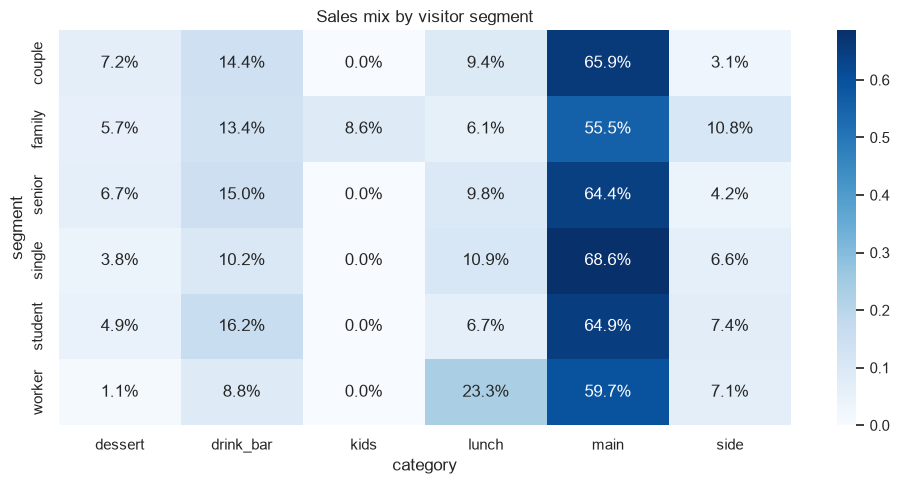

In [4]:
seg=segment.groupby(['segment','category'],observed=True)[['lines','quantity','net_sales','discount','orders']].sum().reset_index()
seg['sales_share']=seg.net_sales/seg.groupby('segment',observed=True).net_sales.transform('sum')
seg['discount_share']=seg.discount/(seg.net_sales+seg.discount)
display(seg.sort_values(['segment','sales_share'],ascending=[True,False]))
share=seg.pivot(index='segment',columns='category',values='sales_share').fillna(0)
fig,ax=plt.subplots(figsize=(10,5));sns.heatmap(share.astype(float),annot=True,fmt='.1%',cmap='Blues',ax=ax);ax.set(title='Sales mix by visitor segment',xlabel='category',ylabel='segment');plt.tight_layout();plt.show()
print('構成比は来店客層・人数・店舗・価格・期間によって変動する。客層による因果効果ではない。')

## 時間帯・カテゴリ別の売上と客層
1行の `order_time` は追加注文ならその注文の時刻。売上は会計時刻ではなく注文明細時刻で集計する。

category,dessert,drink_bar,kids,lunch,main,side
hour,,,,,,
10,0.0089,0.0367,0.0438,0.0000,0.0452,0.0393
11,0.0517,0.0844,0.0814,0.2671,0.0582,0.0888
12,0.0863,0.1063,0.0903,0.3370,0.0734,0.1059
13,0.0907,0.0939,0.0847,0.2934,0.0646,0.0947
14,0.0915,0.0757,0.0808,0.1025,0.0654,0.0768
15,0.0889,0.0792,0.0796,0.0000,0.0852,0.0773
16,0.0925,0.0824,0.0810,0.0000,0.0888,0.0801
17,0.1080,0.1066,0.0938,0.0000,0.1168,0.1004
18,0.1045,0.1051,0.1032,0.0000,0.1275,0.1024


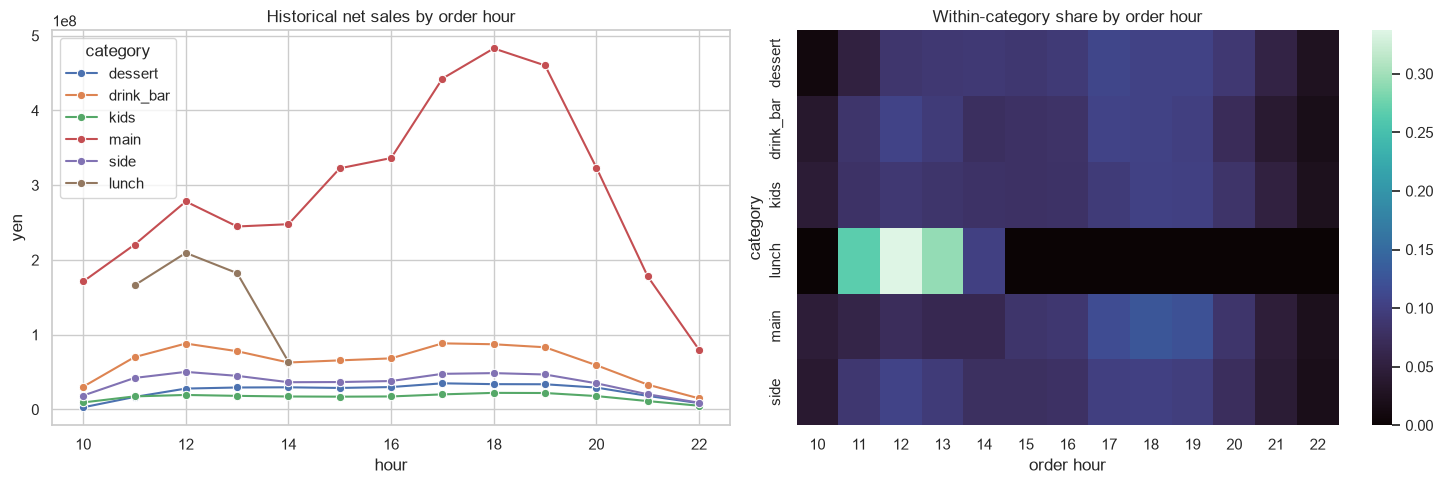

segment,couple,family,senior,single,student,worker
hour,,,,,,
10,0.1502,0.4493,0.0943,0.0451,0.1028,0.1583
11,0.1638,0.3604,0.0920,0.0296,0.0913,0.2627
12,0.1913,0.3254,0.1034,0.0322,0.0944,0.2532
13,0.1873,0.3424,0.1026,0.0293,0.0950,0.2434
14,0.1641,0.4362,0.1044,0.0425,0.1066,0.1461
15,0.1615,0.4322,0.1027,0.0263,0.1853,0.0920
16,0.1595,0.4209,0.1044,0.0227,0.1964,0.0960
17,0.1702,0.3739,0.1013,0.0269,0.2080,0.1197
18,0.2029,0.3882,0.0984,0.0411,0.1478,0.1217


In [5]:
h=hours.groupby(['hour','category'],observed=True)[['lines','quantity','net_sales']].sum().reset_index()
h['category_sales_share']=h.net_sales/h.groupby('category',observed=True).net_sales.transform('sum')
display(h.pivot(index='hour',columns='category',values='category_sales_share').fillna(0))
fig,ax=plt.subplots(1,2,figsize=(15,5));sns.lineplot(data=h,x='hour',y='net_sales',hue='category',marker='o',ax=ax[0]);ax[0].set(title='Historical net sales by order hour',ylabel='yen')
sns.heatmap(h.pivot(index='category',columns='hour',values='category_sales_share').fillna(0).astype(float),cmap='mako',ax=ax[1]);ax[1].set(title='Within-category share by order hour',xlabel='order hour');plt.tight_layout();plt.show()
sh=hourly_segment.groupby(['hour','segment'],observed=True).net_sales.sum().reset_index();sh['share']=sh.net_sales/sh.groupby('hour',observed=True).net_sales.transform('sum')
display(sh.pivot(index='hour',columns='segment',values='share'))

## 客層・カテゴリ別の年次変化
各年の客層内売上構成比。2024年は366日だが、同年内で割るため比率には日数補正を行わない。

In [6]:
annual=segment.groupby(['year','segment','category'],observed=True)[['net_sales','quantity','orders']].sum().reset_index()
annual['share']=annual.net_sales/annual.groupby(['year','segment'],observed=True).net_sales.transform('sum')
display(annual.pivot(index=['segment','category'],columns='year',values='share'))
print('販売期間・価格・企画・店舗別来店構成の変化を含む。')

販売期間・価格・企画・店舗別来店構成の変化を含む。


year                2022   2023   2024
segment category                      
couple  dessert   0.0700 0.0721 0.0730
        drink_bar 0.1472 0.1453 0.1396
        lunch     0.0956 0.0934 0.0923
        main      0.6556 0.6576 0.6639
        side      0.0315 0.0316 0.0312
family  dessert   0.0557 0.0570 0.0585
        drink_bar 0.1364 0.1349 0.1300
        kids      0.0884 0.0875 0.0831
        lunch     0.0626 0.0600 0.0590
        main      0.5489 0.5516 0.5627
        side      0.1080 0.1089 0.1067
senior  dessert   0.0654 0.0675 0.0679
        drink_bar 0.1528 0.1516 0.1452
        lunch     0.1004 0.0979 0.0949
        main      0.6392 0.6408 0.6502
        side      0.0422 0.0422 0.0419
single  dessert   0.0370 0.0377 0.0382
        drink_bar 0.1046 0.1032 0.0982
        lunch     0.1048 0.1083 0.1132
        main      0.6874 0.6843 0.6861
        side      0.0662 0.0665 0.0644
student dessert   0.0479 0.0492 0.0498
        drink_bar 0.1647 0.1632 0.1573
        lunch     0.0692 0.0665 0.0649
        main      0.6444 0.6466 0.6548
        side      0.0738 0.0745 0.0732
worker  dessert   0.0113 0.0114 0.0114
        drink_bar 0.0908 0.0891 0.0853
        lunch     0.2362 0.2298 0.2318
        main      0.5904 0.5987 0.6015
        side      0.0713 0.0710 0.0700

## 解釈・予測時点の注意
- 客層・注文時刻・追加注文の状況は過去の実績。未来の同日の値を特徴量として直接使わない。
- 会計が複数カテゴリを含む場合、カテゴリ別の会計件数を足して全会計数としてはいけない。
- 時間帯・客層別の売上構成は販売時間、価格、商品・店舗構成、季節、企画が混在する。